# Comparación de resultados: nuestro Montecarlo frente al que nos dieron

Ejecutamos nuestro código (montecarlo.ipynb) y la función `MonteCarlo()` que nos dieron, los dos con nuestros parámetros (WMT, MRK, NVDA), y comparamos los resultados.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from numpy.linalg import cholesky

S0 = np.array([1.0, 1.0, 1.0])
mu, E, T, n_times, n_comunes, n_finales = 0.01, 3.0, 5, 20, 5, 100_000
dt = T / n_times
sigma = np.array([0.21915220410541955, 0.23593283496457446, 0.5174176492623017])
rho = np.array([[1.0, 0.23448266076590554, 0.2254536587614545],
                [0.23448266076590554, 1.0, 0.12948744681423088],
                [0.2254536587614545, 0.12948744681423088, 1.0]])

## 1. Nuestro Montecarlo (mismo código que montecarlo.ipynb)

In [2]:
L = np.linalg.cholesky(rho)
rng = np.random.default_rng(11)

Z1 = rng.standard_normal((n_comunes, 3)) @ L.T
e1 = np.exp((mu - 0.5 * sigma**2) * dt + sigma * Z1 * np.sqrt(dt))
S1 = np.cumprod(np.vstack([S0, e1]), axis=0)

Z2 = rng.standard_normal((n_finales, n_times - n_comunes, 3)) @ L.T
e2 = np.exp((mu - 0.5 * sigma**2) * dt + sigma * Z2 * np.sqrt(dt))
S2 = S1[-1] * np.cumprod(e2, axis=1)

X_nuestro = np.concatenate([np.broadcast_to(S1[1:], (n_finales, n_comunes, 3)), S2], axis=1)
payoff_nuestro = np.maximum(np.exp(np.log(X_nuestro / S0).mean(axis=1)).sum(axis=1) - E, 0)

## 2. Montecarlo que nos dan

In [3]:
def MonteCarlo(initial_maturity, S_0, num_sims, num_assets, num_asian_dates, value_date_index, correl_matrix, risk_free_rate, vols):
    init_time_array = np.linspace(0, initial_maturity, num_asian_dates)
    delta_t = initial_maturity / (num_asian_dates - 1)
    num_steps = value_date_index
    num_remaining_steps = num_asian_dates - value_date_index - 1
    inc_W = np.random.normal(size=(num_assets, num_steps), scale=np.sqrt(delta_t))
    m = cholesky(correl_matrix)
    inc_W_correl = np.matmul(m, inc_W)
    inc_W_remaining = np.random.normal(size=(num_sims, num_remaining_steps, num_assets), scale=np.sqrt(delta_t))
    inc_W_correl_remaining = np.matmul(inc_W_remaining, m.T)
    inc_W_correl_remaining = inc_W_correl_remaining.transpose([0, 2, 1])
    aux = np.repeat(inc_W_correl[None, ...], num_sims, axis=0)
    inc_W_correl_total = np.concatenate((aux, inc_W_correl_remaining), axis=2)
    gross_rets_total = np.exp((risk_free_rate - 0.5 * vols**2) * delta_t + vols * inc_W_correl_total)
    S_T = np.cumprod(np.concatenate((np.repeat(S_0.reshape(-1, 1)[None, ...], num_sims, axis=0), gross_rets_total), axis=2), axis=2)
    rets = S_T[:, :, 1:] / np.repeat(S_0.reshape(-1, 1)[None, ...], num_sims, axis=0)
    payoff = np.maximum(np.sum(np.prod(rets, axis=(2))**(1 / (num_asian_dates - 1)), axis=1) - 3, 0)   # corregido: 1/20
    premium = np.mean(payoff * np.exp(-risk_free_rate * (initial_maturity - init_time_array[value_date_index])))
    rets = rets.transpose([0, 2, 1])
    return rets, payoff, premium

np.random.seed(11)
X_dado, payoff_dado, premium_dado = MonteCarlo(T, S0, n_finales, 3, n_times + 1, n_comunes, rho, mu, sigma.reshape(-1, 1))

## 3. Resultados finales

In [4]:
# Sin comienzo común (todo aleatorio) para comparar en igualdad de condiciones
Z = np.random.default_rng(1).standard_normal((n_finales, n_times, 3)) @ L.T
X0_nuestro = np.cumprod(np.exp((mu - 0.5 * sigma**2) * dt + sigma * Z * np.sqrt(dt)), axis=1)
np.random.seed(1)
X0_dado = MonteCarlo(T, S0, n_finales, 3, n_times + 1, 0, rho, mu, sigma.reshape(-1, 1))[0]

casos = {("Con comienzo común (t=5)", "Nuestro"): (X_nuestro, 5), ("Con comienzo común (t=5)", "Dado"): (X_dado, 5),
         ("Sin comienzo común (t=0)", "Nuestro"): (X0_nuestro, 0), ("Sin comienzo común (t=0)", "Dado"): (X0_dado, 0)}
filas = {}
for caso, (X, t) in casos.items():
    payoff = np.maximum(np.exp(np.log(X).mean(axis=1)).sum(axis=1) - E, 0)
    valor = payoff * np.exp(-mu * (n_times - t) * dt)
    filas[caso] = {"prima": valor.mean(), "error estándar": valor.std() / np.sqrt(n_finales),
                   "payoff medio": payoff.mean(), "% payoff > 0": 100 * (payoff > 0).mean()}
pd.DataFrame(filas).T.round(4)

prima  error estándar  payoff medio  \
Con comienzo común (t=5) Nuestro  0.3052          0.0015        0.3168   
                         Dado     0.0111          0.0002        0.0115   
Sin comienzo común (t=0) Nuestro  0.3080          0.0020        0.3238   
                         Dado     0.3071          0.0020        0.3229   

                                  % payoff > 0  
Con comienzo común (t=5) Nuestro        53.433  
                         Dado            4.198  
Sin comienzo común (t=0) Nuestro        38.922  
                         Dado           38.762

## Conclusión

- **Con comienzo común las primas no coinciden.** Cada código sortea su propio comienzo (los 5 primeros trimestres) y la prima depende mucho de él.
- **Sin comienzo común las dos primas son iguales salvo el azar** (diferencia dentro del error estándar): los dos códigos calculan lo mismo.

**Por eso vamos a trabajar con nuestros datos:** dan el mismo resultado que el código que nos dieron (ya corregido), y además nuestro Montecarlo está documentado y es reproducible con su semilla.

## 4. Comparación con la fórmula cerrada de BBVA

La fórmula cerrada de BBVA (`BasketGeomAsian`) no valora nuestro payoff (la suma de las tres medias geométricas menos 3), sino el de la **media geométrica conjunta de la cesta** (los 60 ratios) menos 1, que es el único que tiene fórmula exacta. Por eso, con **las mismas trayectorias de nuestro Montecarlo**, calculamos los dos payoffs:

- **Payoff del reto:** max(suma de las 3 medias geométricas − 3, 0). Es nuestra prima.
- **Payoff de la cesta:** max(media geométrica de los 60 ratios − 1, 0). Es el que se compara con la fórmula.

Si el Montecarlo de la cesta coincide con la fórmula, queda comprobado que nuestras trayectorias (volatilidades, correlaciones y Cholesky) están bien, y por tanto también la prima del reto, que sale de esas mismas trayectorias.

A la fórmula se le pasa el histórico empezando por S0 (columna de unos) y hasta el trimestre de valoración. En la celda de comparación del notebook de BBVA se pasaba `simu2[1,:,:(i+1)]`, que empieza en t1 e incluye un trimestre futuro.

In [6]:
from scipy.stats import norm

def Black(Forward, Strike, TTM, rate, Vol, IsCall):
    """Fórmula de Black (copiada del notebook de BBVA)."""
    N = norm.cdf
    if TTM > 0:
        d1 = (np.log(Forward / Strike) + (Vol * Vol / 2) * TTM) / (Vol * np.sqrt(TTM))
        d2 = (np.log(Forward / Strike) + (-Vol * Vol / 2) * TTM) / (Vol * np.sqrt(TTM))
        if IsCall:
            return (Forward * N(d1) - Strike * N(d2)) * np.exp(-rate * TTM)
        return (-Forward * N(-d1) + Strike * N(-d2)) * np.exp(-rate * TTM)
    return np.maximum(Forward - Strike, 0) if IsCall else np.maximum(-Forward + Strike, 0)


def BasketGeomAsian(num_asian_dates, value_date_index, risk_free_rate, num_assets,
                    assets_vol, assets_correl, initial_maturity, price_history, IsCall):
    """Fórmula cerrada de BBVA (copiada de su notebook): call asiática sobre la media
    geométrica de la cesta. price_history: (activos, value_date_index + 1), con S0 en la columna 0."""
    init_time_array = np.linspace(0, initial_maturity, num_asian_dates)
    pending_times_array = init_time_array[value_date_index + 1:] - init_time_array[value_date_index]
    mu_ = np.sum(risk_free_rate - 0.5 * assets_vol * assets_vol) * np.sum(pending_times_array) / (num_assets * (num_asian_dates - 1))
    diag_vol = np.diag(assets_vol.reshape(-1))
    cov_matrix = np.matmul(diag_vol, np.matmul(assets_correl, diag_vol))
    xx, yy = np.meshgrid(pending_times_array, pending_times_array, sparse=True)
    z = np.minimum(xx, yy)
    V = np.sum(cov_matrix) * np.sum(z) / (num_assets * num_assets * (num_asian_dates - 1) * (num_asian_dates - 1))
    Forward = np.power(np.prod(price_history[:, 1:value_date_index + 1] / price_history[:, 0].reshape(-1, 1)), 1.0 / (num_assets * (num_asian_dates - 1)))
    Forward *= np.power(np.prod(price_history[:, value_date_index] / price_history[:, 0]), (num_asian_dates - value_date_index - 1) / (num_assets * (num_asian_dates - 1)))
    Forward *= np.exp(mu_ + 0.5 * V)
    remaining_maturity = initial_maturity - init_time_array[value_date_index]
    return Black(Forward, 1.0, remaining_maturity, risk_free_rate, np.sqrt(V / remaining_maturity), IsCall)

### 4.1 Con las trayectorias de la sección 3

Primero con las mismas simulaciones de arriba: sin comienzo común (valoración hoy, t = 0) y con comienzo común (valoración en el trimestre 5).

In [7]:
def primas(X, t, historico):
    """Primas en el trimestre t con las trayectorias X (sin S0) y el histórico hasta t (con S0)."""
    desc = np.exp(-mu * (n_times - t) * dt)
    pay_reto = np.maximum(np.exp(np.log(X).mean(axis=1)).sum(axis=1) - E, 0)
    pay_cesta = np.maximum(np.exp(np.log(X).mean(axis=(1, 2))) - 1, 0)
    return {"prima reto": desc * pay_reto.mean(),
            "prima cesta (MC)": desc * pay_cesta.mean(),
            "IC 95 % cesta": 1.96 * desc * pay_cesta.std(ddof=1) / np.sqrt(len(X)),
            "fórmula BBVA": BasketGeomAsian(n_times + 1, t, mu, 3, sigma.reshape(-1, 1), rho, T, historico, True)}

tabla_formula = pd.DataFrame({"Sin comienzo común (t=0)": primas(X0_nuestro, 0, np.ones((3, 1))),
                              "Con comienzo común (t=5)": primas(X_nuestro, 5, S1.T)}).T
tabla_formula["diferencia cesta"] = tabla_formula["prima cesta (MC)"] - tabla_formula["fórmula BBVA"]
tabla_formula.round(4)

,prima reto,prima cesta (MC),IC 95 % cesta,fórmula BBVA,diferencia cesta
Sin comienzo común (t=0),0.3080,0.0768,0.0010,0.0760,0.0008
Con comienzo común (t=5),0.3052,0.0817,0.0008,0.0818,-0.0001


### 4.2 En todos los trimestres

Para ver la comparación en cada instante usamos una trayectoria de referencia como histórico observado: el comienzo común (trimestres 0 a 5) y, desde ahí, la simulación cuyo payoff está más cerca del payoff medio, para que la opción no quede descartada a mitad de camino. En cada trimestre t se fija el histórico hasta t y se simulan 100.000 veces los trimestres que faltan; la prima se descuenta desde el vencimiento hasta t.

In [8]:
h_ref = np.abs(payoff_nuestro - payoff_nuestro.mean()).argmin()   # simulación con payoff más cercano a la media
ref = np.vstack([S1, S2[h_ref]])       # trayectoria de referencia, trimestres 0 a 20: (21, 3)

def valorar_en(t, n_sims=n_finales, seed=100):
    rng_t = np.random.default_rng(seed + t)
    Z = rng_t.standard_normal((n_sims, n_times - t, 3)) @ L.T
    futuro = ref[t] * np.cumprod(np.exp((mu - 0.5 * sigma**2) * dt + sigma * Z * np.sqrt(dt)), axis=1)
    Xt = np.concatenate([np.broadcast_to(ref[1:t + 1], (n_sims, t, 3)), futuro], axis=1)   # (n_sims, 20, 3)
    return {"trimestre": t, **primas(Xt, t, ref[:t + 1].T)}

comparacion = pd.DataFrame([valorar_en(t) for t in range(n_times)]).set_index("trimestre")
comparacion["diferencia cesta"] = comparacion["prima cesta (MC)"] - comparacion["fórmula BBVA"]
comparacion.round(4)

,prima reto,prima cesta (MC),IC 95 % cesta,fórmula BBVA,diferencia cesta
trimestre,,,,,
0,0.3092,0.0769,0.0010,0.0760,0.0009
1,0.5841,0.1506,0.0014,0.1510,-0.0004
2,0.3497,0.0905,0.0010,0.0897,0.0008
3,0.4832,0.1290,0.0012,0.1286,0.0004
4,0.3482,0.0884,0.0009,0.0887,-0.0004
5,0.3061,0.0820,0.0008,0.0818,0.0002
6,0.4518,0.1173,0.0009,0.1173,-0.0000
7,0.6687,0.1682,0.0010,0.1681,0.0001
8,0.4646,0.1153,0.0008,0.1151,0.0002


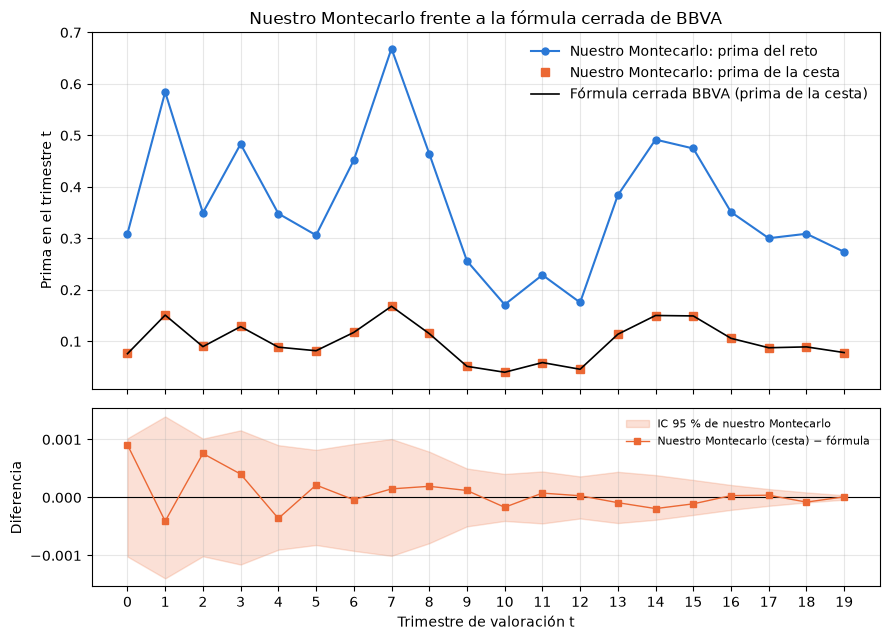

In [12]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 6.5), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
tq = comparacion.index

ax1.plot(tq, comparacion["prima reto"], "o-", color="#2a78d6", lw=1.5, ms=5,
         label="Nuestro Montecarlo: prima del reto")
ax1.plot(tq, comparacion["prima cesta (MC)"], "s", color="#eb6834", ms=6,
         label="Nuestro Montecarlo: prima de la cesta")
ax1.plot(tq, comparacion["fórmula BBVA"], "-", color="black", lw=1.2,
         label="Fórmula cerrada BBVA (prima de la cesta)")
ax1.set_ylabel("Prima en el trimestre t")
ax1.set_title("Nuestro Montecarlo frente a la fórmula cerrada de BBVA")
ax1.legend(frameon=False)
ax1.grid(alpha=0.3)

ax2.axhline(0, color="black", lw=0.8)
ax2.fill_between(tq, -comparacion["IC 95 % cesta"], comparacion["IC 95 % cesta"], color="#eb6834", alpha=0.2,
                 label="IC 95 % de nuestro Montecarlo")
ax2.plot(tq, comparacion["diferencia cesta"], "s-", color="#eb6834", ms=4, lw=1, label="Nuestro Montecarlo (cesta) − fórmula")
ax2.set_xlabel("Trimestre de valoración t")
ax2.set_ylabel("Diferencia")
ax2.set_xticks(range(n_times))
ax2.legend(frameon=False, fontsize=8)
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Conclusión de la comparación con la fórmula cerrada

- **Nuestro Montecarlo coincide con la fórmula cerrada de BBVA** cuando se valora el mismo payoff (el de la cesta): la mayor diferencia en los 20 trimestres es de 0,0009, y en los 20 trimestres la diferencia queda dentro del intervalo de confianza del 95 % del Montecarlo. Esto confirma que nuestras trayectorias están bien construidas.
- **La prima del reto es mayor que la de la fórmula** (unas 3,8 veces de mediana) porque valora otro payoff: suma las tres medias geométricas en lugar de promediarlas en una sola. No es un error del modelo.
- **La fórmula cerrada solo sirve como referencia para el payoff de la cesta.** Para nuestra prima, la referencia es el propio Montecarlo, validado con esta comparación.